In [4]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 27.8 MB/s eta 0:00:00


In [5]:
import os
import torch
from ultralytics import YOLO
import cv2
import glob
import random

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [6]:
DATASET_PATH = '/content/drive/MyDrive/snownet/snowdetection.v2i.yolov11/data.yaml'

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Используется устройство: {device}")

if not os.path.exists(DATASET_PATH):
    print(f"Ошибка: Файл data.yaml не найден по пути: {DATASET_PATH}")
    print("Убедитесь, что вы загрузили папку с датасетом в правильное место.")
else:
    print("Файл конфигурации датасета найден.")

Используется устройство: cuda
Файл конфигурации датасета найден.


In [7]:
model = YOLO('yolo11n.pt').to(device)

print("\nНачинаю обучение модели...")
try:
    results = model.train(
        data=DATASET_PATH,
        epochs=50,
        imgsz=640,
        patience=20,
        device=device,
        verbose=True
    )
    print("Обучение завершено. Лучшая модель сохранена.")
    trained_model_path = os.path.join('runs', 'detect', 'train', 'weights', 'best.pt')
except Exception as e:
    print(f"Произошла ошибка во время обучения: {e}")
    trained_model_path = None


Начинаю обучение модели...
Ultralytics 8.3.201 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/snownet/snowdetection.v2i.yolov11/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overl

In [10]:
if trained_model_path and os.path.exists(trained_model_path):
    print("\nНачинаю предсказание на 10 случайных тестовых изображениях.")

    trained_model = YOLO(trained_model_path)

    test_images = glob.glob('/content/drive/MyDrive/snownet/snowdetection.v2i.yolov11/test/images/*.jpg')

    if not test_images:
        print("Ошибка: Тестовые изображения не найдены в папке test/images.")
    else:
        num_images_to_save = 10
        if len(test_images) < num_images_to_save:
            num_images_to_save = len(test_images)
        selected_images = random.sample(test_images, num_images_to_save)

        output_dir = 'yolo_results_snow_detection'
        if not os.path.exists(output_dir):
            os.makedirs(output_dir)

        for i, image_path in enumerate(selected_images):
            print(f"\nОбработка изображения {i+1}/{num_images_to_save}: {os.path.basename(image_path)}")

            results = trained_model(image_path, conf=0.25, verbose=False)

            result_image = results[0].plot()

            output_image_path = os.path.join(output_dir, f'result_{i+1}_{os.path.basename(image_path)}')
            cv2.imwrite(output_image_path, result_image)

            print(f"Изображение с результатом успешно сохранено по пути: {output_image_path}")

else:
    print("\nОшибка: Не удалось найти обученную модель для предсказания.")
    print("Убедитесь, что обучение прошло без критических ошибок.")


Начинаю предсказание на 10 случайных тестовых изображениях.

Обработка изображения 1/10: 203_jpg.rf.1dd3f22a3590990e73cb3e9aec7b215e.jpg
Изображение с результатом успешно сохранено по пути: yolo_results_snow_detection/result_1_203_jpg.rf.1dd3f22a3590990e73cb3e9aec7b215e.jpg

Обработка изображения 2/10: Data_AI-1657-_jpg.rf.5c1210d2e9c89cf76ec03470f804365d.jpg
Изображение с результатом успешно сохранено по пути: yolo_results_snow_detection/result_2_Data_AI-1657-_jpg.rf.5c1210d2e9c89cf76ec03470f804365d.jpg

Обработка изображения 3/10: Image-172-_jpg.rf.e3b1c1c2554dd9598f438f8081b761ef.jpg
Изображение с результатом успешно сохранено по пути: yolo_results_snow_detection/result_3_Image-172-_jpg.rf.e3b1c1c2554dd9598f438f8081b761ef.jpg

Обработка изображения 4/10: th-51-_png_jpg.rf.21d9c3977578e7ba4610fd3437082702.jpg
Изображение с результатом успешно сохранено по пути: yolo_results_snow_detection/result_4_th-51-_png_jpg.rf.21d9c3977578e7ba4610fd3437082702.jpg

Обработка изображения 5/10: th


Полные результаты обучения находятся в файле: runs/detect/train/results.csv

Графики, сгенерированные Ultralytics, находятся в папке: runs/detect/train
Вы можете открыть их в Google Colab.
Предупреждение: Файл 'PR_curve.png' не найден.
Предупреждение: Файл 'F1_curve.png' не найден.


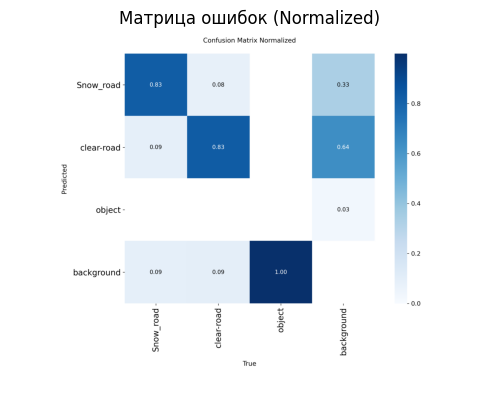

In [12]:
import matplotlib.pyplot as plt

def show_metrics_and_visualizations(run_dir):
    metrics_path = os.path.join(run_dir, 'results.csv')
    if os.path.exists(metrics_path):
        print("\nПолные результаты обучения находятся в файле:", metrics_path)

    print("\nГрафики, сгенерированные Ultralytics, находятся в папке:", run_dir)
    print("Вы можете открыть их в Google Colab.")

    metrics_to_show = {
        'Precision-Recall': 'PR_curve.png',
        'F1-Confidence': 'F1_curve.png',
        'Матрица ошибок (Normalized)': 'confusion_matrix_normalized.png'
    }

    plt.figure(figsize=(15, 5))
    for i, (title, filename) in enumerate(metrics_to_show.items()):
        file_path = os.path.join(run_dir, filename)
        if os.path.exists(file_path):
            img = cv2.imread(file_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax = plt.subplot(1, 3, i + 1)
            ax.imshow(img)
            ax.set_title(title)
            ax.axis('off')
        else:
            print(f"Предупреждение: Файл '{filename}' не найден.")

    plt.tight_layout()
    plt.show()

results_dir = os.path.join('runs', 'detect', 'train')
if os.path.exists(results_dir):
    show_metrics_and_visualizations(results_dir)
else:
    print("\nПапка с результатами обучения не найдена. Убедитесь, что обучение завершилось успешно.")


In [14]:
def process_my_pics(model_path, pics_dir):
    if not os.path.exists(model_path):
        print(f"Ошибка: Обученная модель не найдена по пути: {model_path}")
        return

    model = YOLO(model_path)

    input_dir = pics_dir
    output_dir = 'my_pics_results'

    if not os.path.exists(input_dir):
        print(f"Ошибка: Папка '{input_dir}' не найдена. Создайте её и добавьте свои изображения.")
        return

    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
        print(f"Создана папка для результатов: {output_dir}")

    new_images = glob.glob(os.path.join(input_dir, '*.jpg'))
    new_images.extend(glob.glob(os.path.join(input_dir, '*.jpeg')))
    new_images.extend(glob.glob(os.path.join(input_dir, '*.png')))

    if not new_images:
        print(f"В папке '{input_dir}' не найдено изображений для обработки.")
        return

    for i, image_path in enumerate(new_images):
        print(f"Обработка изображения {i+1}/{len(new_images)}: {os.path.basename(image_path)}")
        try:
            results = model(image_path, conf=0.25, verbose=False)
            result_image = results[0].plot()
            output_image_path = os.path.join(output_dir, os.path.basename(image_path))
            cv2.imwrite(output_image_path, result_image)
            print(f"Результат сохранен по пути: {output_image_path}")
        except Exception as e:
            print(f"Ошибка при обработке изображения {image_path}: {e}")

process_my_pics(trained_model_path, '/content/drive/MyDrive/snownet/my_pics')

Создана папка для результатов: my_pics_results
Обработка изображения 1/7: sa2.jpg
Результат сохранен по пути: my_pics_results/sa2.jpg
Обработка изображения 2/7: sa5.jpg
Результат сохранен по пути: my_pics_results/sa5.jpg
Обработка изображения 3/7: sa3.jpg
Результат сохранен по пути: my_pics_results/sa3.jpg
Обработка изображения 4/7: sa.jpg
Результат сохранен по пути: my_pics_results/sa.jpg
Обработка изображения 5/7: sa7.jpg
Результат сохранен по пути: my_pics_results/sa7.jpg
Обработка изображения 6/7: sa4.jpg
Результат сохранен по пути: my_pics_results/sa4.jpg
Обработка изображения 7/7: sa6.jpg
Результат сохранен по пути: my_pics_results/sa6.jpg
